In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pylatexenc

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

simulator = AerSimulator()

print("Qiskit environment is ready.")

Qiskit environment is ready.


# **Quantum Teleporation**

## 1. **What is quantum teleportation?**

Suppose Alice possesses a qubit in an unknown quantum state:

$$
|\psi\rangle = \alpha|0\rangle+\beta|1\rangle
$$

where

$$
|\alpha|^2+|\beta|^2=1.
$$

Alice wants Bob to obtain this quantum state, even though they are physically separated.

Quantum teleportation allows Alice to transfer the **quantum state** to Bob using:

1. A shared entangled pair.
2. A joint operation and measurement by Alice.
3. Two classical bits sent from Alice to Bob.
4. Correction gates applied by Bob.

Alice does not send the original qubit to Bob. After Alice's measurement, the original state is no longer available on her input qubit.

### The three qubits

We will use three qubits:

- $q_0$: Alice's original state $|\psi\rangle$.
- $q_1$: Alice's half of the shared entangled pair.
- $q_2$: Bob's half of the shared entangled pair.

Initially,

$$
|\psi\rangle_{q_0}|0\rangle_{q_1}|0\rangle_{q_2}.
$$

Alice and Bob first create a Bell pair between $q_1$ and $q_2$:

$$
|\Phi^+\rangle
=
\frac{|00\rangle+|11\rangle}{\sqrt{2}}.
$$

The shared state is then

$$
|\psi\rangle_{q_0}\otimes
\frac{|00\rangle_{q_1q_2}+|11\rangle_{q_1q_2}}{\sqrt{2}}.
$$

**Important:** Alice and Bob need to share the entangled pair before the teleportation protocol begins.

### 1.1. The Teleportation Circuit

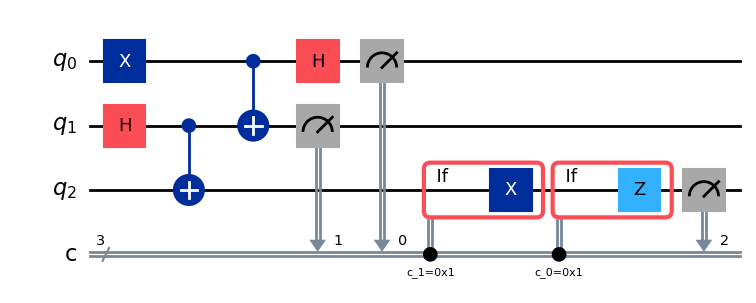

In [ ]:
qc_teleport_diagram = QuantumCircuit(3, 3)

# Prepare an example input state |1>
qc_teleport_diagram.x(0)

# Create a Bell pair between Alice's q1 and Bob's q2
qc_teleport_diagram.h(1)
qc_teleport_diagram.cx(1, 2)

# Alice's Bell-basis measurement circuit
qc_teleport_diagram.cx(0, 1)
qc_teleport_diagram.h(0)

# Alice measures her two qubits
qc_teleport_diagram.measure(0, 0)
qc_teleport_diagram.measure(1, 1)

# Bob's corrections, controlled by Alice's classical results
with qc_teleport_diagram.if_test((qc_teleport_diagram.clbits[1], 1)):
    qc_teleport_diagram.x(2)

with qc_teleport_diagram.if_test((qc_teleport_diagram.clbits[0], 1)):
    qc_teleport_diagram.z(2)

# Bob measures his qubit
qc_teleport_diagram.measure(2, 2)

display(qc_teleport_diagram.draw("mpl", fold=-1))

### Understanding the gates

| Gate | Purpose |
|---|---|
| $H$ on $q_1$ | Creates superposition for the Bell pair. |
| $\mathrm{CNOT}(q_1,q_2)$ | Entangles Alice's and Bob's qubits. |
| $\mathrm{CNOT}(q_0,q_1)$ | Couples the unknown input to Alice's entangled qubit. |
| $H$ on $q_0$ | Completes Alice's Bell-basis measurement circuit. |
| Measurement of $q_0,q_1$ | Produces two classical bits. |
| Conditional $X$ on $q_2$ | Corrects a bit flip when Alice's second measurement result is 1. |
| Conditional $Z$ on $q_2$ | Corrects a phase flip when Alice's first measurement result is 1. |

The order matters: Alice measures first, communicates the two classical bits, and Bob applies the appropriate corrections.

### 1.2. Run the teleportation protocol
For the first demonstration, teleport the simple input state $|1\rangle$. This makes it easy to check whether Bob receives the correct computational-basis state.

Measurement counts: {'110': 258, '101': 256, '111': 272, '100': 238}


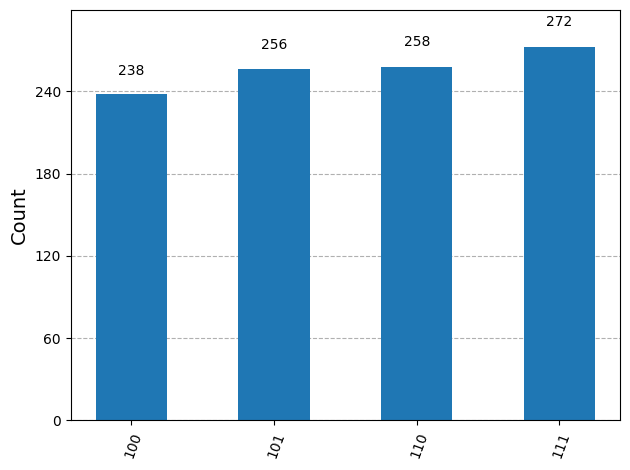

In [ ]:
result = simulator.run(
    transpile(qc_teleport_diagram, simulator),
    shots=1024
).result()

teleport_counts = result.get_counts()

print("Measurement counts:", teleport_counts)
display(plot_histogram(teleport_counts))

### 1.3. **Teleport an arbitrary qubit state**


An arbitrary pure qubit can be written as

$$
|\psi\rangle
=
\cos\left(\frac{\theta}{2}\right)|0\rangle
+
e^{i\phi}\sin\left(\frac{\theta}{2}\right)|1\rangle.
$$

We can prepare this state using

$$
R_y(\theta)
\quad\text{followed by}\quad
R_z(\phi).
$$

The $R_z$ gate adds a relative phase. A global phase does not affect measurement probabilities.

We can therefore replace the $X$ gate that prepared $|1\rangle$ with the two rotation gates below. The rest of the teleportation circuit stays the same.

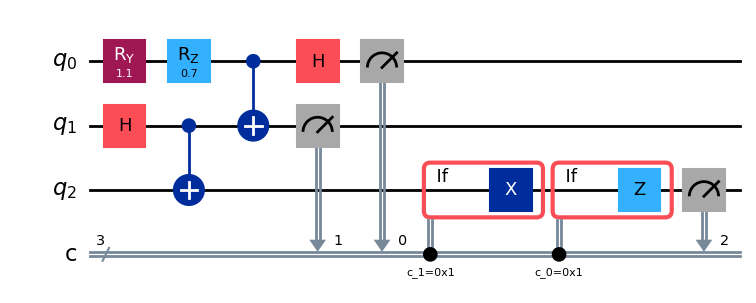

{'101': 74, '111': 77, '011': 163, '000': 181, '010': 164, '100': 86, '110': 70, '001': 209}


In [ ]:
theta = 1.1
phi = 0.7

qc_teleport_general = QuantumCircuit(3, 3)

# Prepare an arbitrary input state on q0
qc_teleport_general.ry(theta, 0)
qc_teleport_general.rz(phi, 0)

# Shared Bell pair
qc_teleport_general.h(1)
qc_teleport_general.cx(1, 2)

# Alice's operations
qc_teleport_general.cx(0, 1)
qc_teleport_general.h(0)

# Alice's measurements
qc_teleport_general.measure(0, 0)
qc_teleport_general.measure(1, 1)

# Bob's conditional corrections
with qc_teleport_general.if_test((qc_teleport_general.clbits[1], 1)):
    qc_teleport_general.x(2)

with qc_teleport_general.if_test((qc_teleport_general.clbits[0], 1)):
    qc_teleport_general.z(2)

# Bob's final measurement
qc_teleport_general.measure(2, 2)

display(qc_teleport_general.draw("mpl", fold=-1))

result = simulator.run(
    transpile(qc_teleport_general, simulator),
    shots=1024
).result()

print(result.get_counts())

**What should you understand here?**

The circuit implements the teleportation protocol for a general input state, not just $|0\rangle$ or $|1\rangle$.

However, measuring Bob's qubit in the computational basis gives only measurement statistics. To verify that an arbitrary quantum state has been transferred, we would need a stronger test, such as state tomography or a state-fidelity calculation.

### Teleportation in one sentence

Alice's two measurement results tell Bob which correction gates to apply so that his qubit recovers the original quantum state.